# Digital Advertising Budget Optimizer
## Notebook 07 — Final Report & GitHub Package

**Goal:** turn the results of Notebooks 01–06 into deliverables:
1. **Completeness check:** confirms every earlier notebook ran
2. **Executive dashboard:** one image summarising the project for management
3. **Final report:** `outputs/reports/FINAL_REPORT.md`, with every number pulled live from the saved results
4. **GitHub files:** `README.md`, `requirements.txt`, `.gitignore`, `LICENSE`
5. **Upload package:** a clean folder and zip containing exactly what belongs on GitHub

**Before running:** fill in your name and GitHub username in the first code cell.

**Requires:** Notebooks 01–06 completed. Runtime < 1 min.

In [1]:
# ============================================================
# 1. Setup: fill in your details
# ============================================================
AUTHOR_NAME = "Hamza Halim"                 # appears in README, report and LICENSE
GITHUB_USERNAME = "hamzahalim-dev"  # used for the "Open in Colab" links
REPO_NAME = "ad-budget-optimizer"
COURSE = "Big Data Analytics"             # optional, shown in the README

import os, sys, json, shutil, glob, zipfile, importlib, warnings, datetime as dt
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

PROJECT_NAME = "ad-budget-optimizer"
if IN_COLAB:
    drive.mount("/content/drive")
    MYDRIVE = Path("/content/drive/MyDrive")
    DRIVE_DIR = MYDRIVE / PROJECT_NAME
else:
    MYDRIVE = Path.cwd()
    DRIVE_DIR = Path.cwd() / PROJECT_NAME

SRC_DIR = DRIVE_DIR / "src"
FIG_DIR, REP_DIR, BENCH_DIR = (DRIVE_DIR / "outputs" / d for d in ("figures", "reports", "benchmarks"))
sys.path.insert(0, str(SRC_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
import kpis, viz
importlib.reload(kpis); importlib.reload(viz)
viz.apply_style()
ORDER = viz.PLATFORM_ORDER
TODAY = dt.date.today().strftime("%d %B %Y")
print("Project folder:", DRIVE_DIR)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/ad-budget-optimizer


## 2. Completeness check

In [2]:
# ============================================================
# 2. Completeness check: does every notebook's output exist?
# ============================================================
EXPECTED = {
    "01 Data generation": ["config/generator_config.json", "src/adgen.py", "data/raw/csv/ads_10m.csv",
                           "outputs/reports/01_kpi_validation_roas.csv"],
    "02 EDA & KPIs":      ["outputs/reports/02_kpi_platform.csv", "outputs/reports/02_key_insights.md",
                           "data/processed/daily_platform_10m.parquet", "outputs/figures/02_platform_performance.png"],
    "03 MapReduce":       ["src/mapreduce/mapper.py", "outputs/reports/03_validation_vs_pandas.csv",
                           "outputs/benchmarks/03_mapreduce_scaling.csv", "outputs/reports/03_findings.md"],
    "04 Spark":           ["outputs/reports/04_validation_vs_pandas.csv", "outputs/benchmarks/04_spark_scaling.csv",
                           "outputs/reports/04_findings.md"],
    "05 Benchmark":       ["outputs/benchmarks/05_benchmark_summary.csv", "outputs/benchmarks/05_environment.json",
                           "outputs/reports/05_findings.md"],
    "06 Recommendation":  ["src/engine.py", "outputs/reports/06_recommendation.json",
                           "outputs/reports/06_scenarios.csv", "outputs/reports/06_findings.md"],
}
check = pd.DataFrame([{"notebook": nb, "files_expected": len(files),
                       "files_found": sum((DRIVE_DIR / f).exists() for f in files),
                       "missing": ", ".join(f for f in files if not (DRIVE_DIR / f).exists())}
                      for nb, files in EXPECTED.items()]).set_index("notebook")
check["status"] = np.where(check.files_found == check.files_expected, "✅", "❌")
display(check)
assert (check.status == "✅").all(), "Some notebooks have not been run. Run the ❌ ones first, then re-run this notebook."

read_csv = lambda name, **kw: pd.read_csv(DRIVE_DIR / name, **kw)
read_md = lambda name: (DRIVE_DIR / name).read_text().strip()

overall = read_csv("outputs/reports/02_kpi_overall.csv", index_col=0)["value"]
plat = read_csv("outputs/reports/02_kpi_platform.csv", index_col=0).reindex(ORDER)
val03 = read_csv("outputs/reports/03_validation_vs_pandas.csv", index_col=0)
val04 = read_csv("outputs/reports/04_validation_vs_pandas.csv", index_col=0)
bench = read_csv("outputs/benchmarks/05_benchmark_summary.csv")
env = json.loads((BENCH_DIR / "05_environment.json").read_text())
rec = json.loads((REP_DIR / "06_recommendation.json").read_text())
scen = read_csv("outputs/reports/06_scenarios.csv", index_col=0)
sizes = read_csv("outputs/reports/06_data_size_sensitivity.csv", index_col=0)
valid06 = read_csv("outputs/reports/06_validation.csv", index_col=0)
cfg = json.loads((DRIVE_DIR / "config/generator_config.json").read_text())

ENGINES = list(dict.fromkeys(bench.engine))
bench_tbl = bench.pivot(index="dataset", columns="engine", values="median_s")
bench_tbl = bench_tbl.reindex([d for d in ["10k", "100k", "1m", "10m", "50m"] if d in bench_tbl.index])[ENGINES]
rec_rs = pd.Series(rec["recommended_rs"]).reindex(ORDER)
cur_rs = pd.Series(rec["current_rs"]).reindex(ORDER)
mr_real = not any("sim" in e for e in ENGINES)
print("All results loaded ✅" + ("" if mr_real else "   (note: MapReduce timings are from the pipe simulation)"))

,files_expected,files_found,missing,status
notebook,,,,
01 Data generation,4,4,,✅
02 EDA & KPIs,4,4,,✅
03 MapReduce,4,4,,✅
04 Spark,3,3,,✅
05 Benchmark,3,3,,✅
06 Recommendation,4,4,,✅


All results loaded ✅


## 3. Executive dashboard

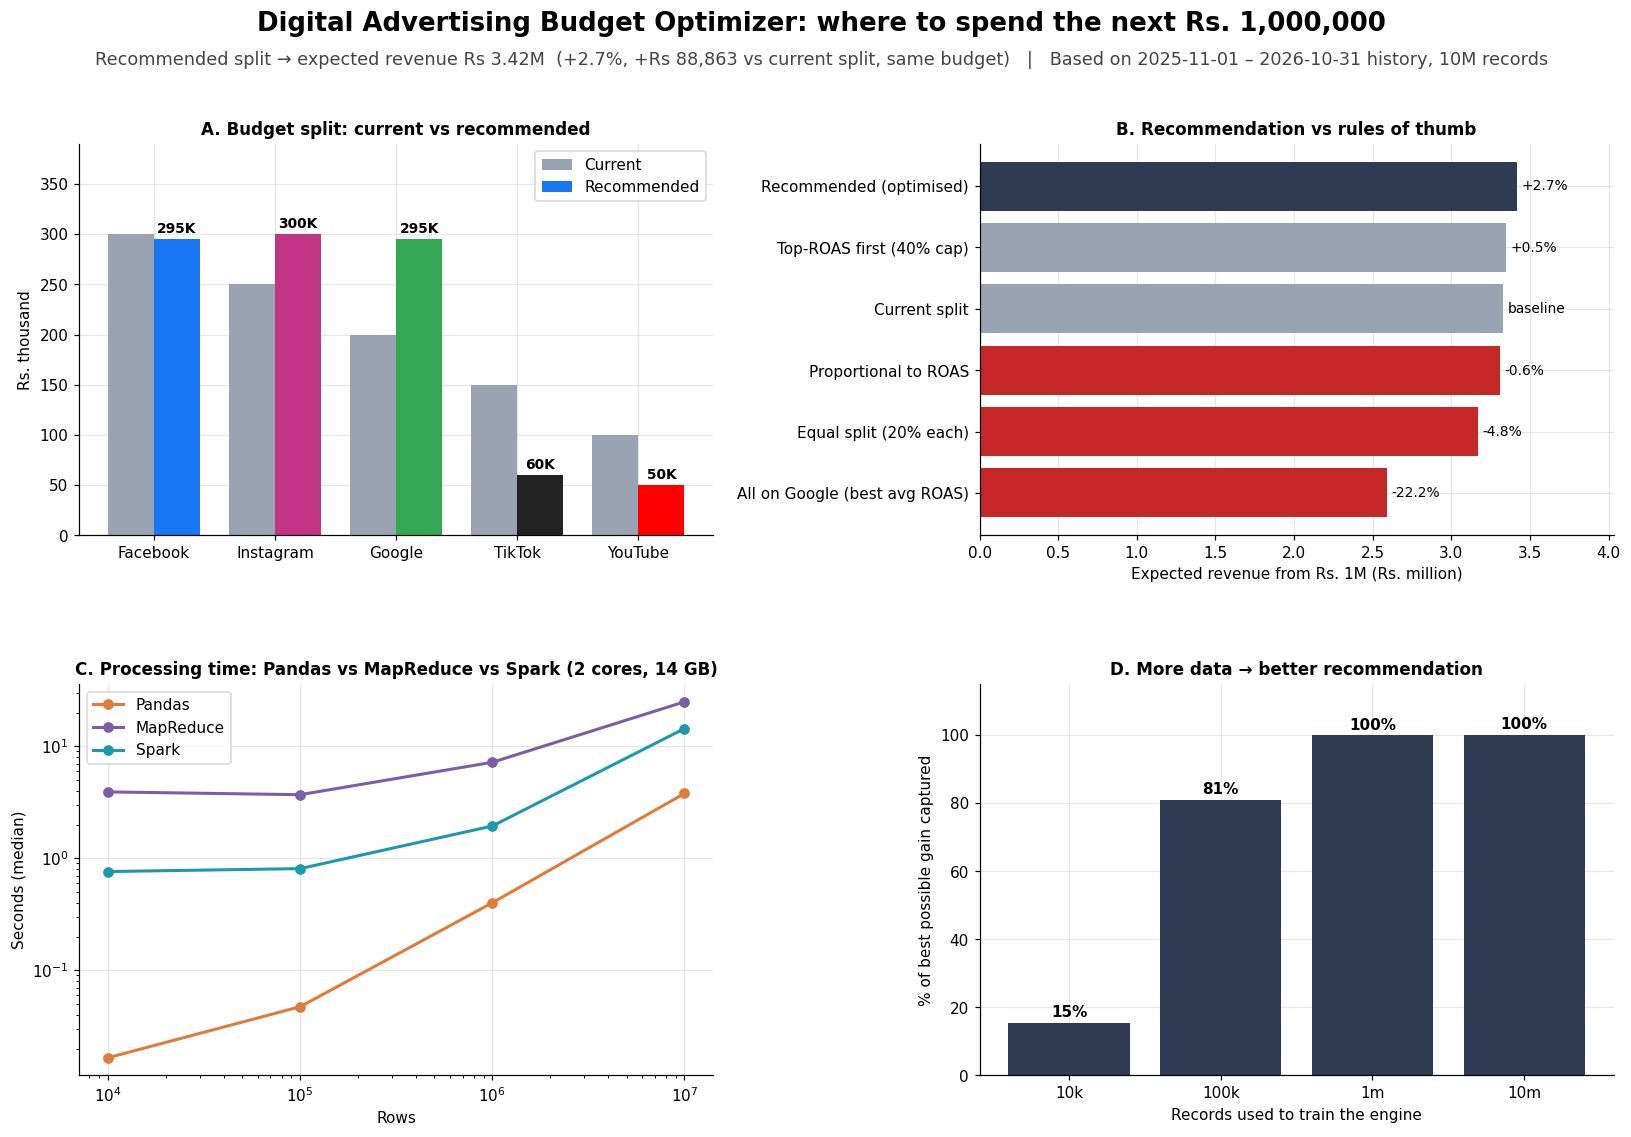

In [3]:
# ============================================================
# 3. Executive dashboard: one image for management and the README
# ============================================================
ENGINE_COLORS = dict(zip(ENGINES, ["#E07B39", "#7B5EA7", "#1B9AAA"]))
fig = plt.figure(figsize=(18, 11))
gs = fig.add_gridspec(2, 2, hspace=0.38, wspace=0.42)
fig.suptitle(f"Digital Advertising Budget Optimizer: where to spend the next Rs. {rec['budget']:,}",
             fontsize=17, fontweight="bold", y=0.99)
fig.text(0.5, 0.945,
         f"Recommended split → expected revenue Rs {rec['expected_revenue_rs'] / 1e6:.2f}M  "
         f"({rec['uplift_pct']:+.1f}%, +Rs {rec['uplift_rs']:,.0f} vs current split, same budget)   |   "
         f"Based on {cfg['date_range'][0]} – {cfg['date_range'][1]} history, 10M records",
         ha="center", fontsize=11.5, color="#444")

# A. Budget split
a = fig.add_subplot(gs[0, 0])
x, w = np.arange(len(ORDER)), 0.38
a.bar(x - w/2, cur_rs / 1e3, w, color=viz.NEUTRAL, label="Current")
b = a.bar(x + w/2, rec_rs / 1e3, w, color=viz.colors_for(ORDER), label="Recommended")
a.bar_label(b, labels=[f"{v / 1e3:,.0f}K" for v in rec_rs], padding=2, fontweight="bold", fontsize=9)
a.set_xticks(x, ORDER); a.set_ylabel("Rs. thousand"); a.legend(loc="upper right")
a.set_ylim(0, max(cur_rs.max(), rec_rs.max()) / 1e3 * 1.3)
a.set_title("A. Budget split: current vs recommended")

# B. Scenarios
a = fig.add_subplot(gs[0, 1])
s = scen.sort_values("expected_revenue_Rs")
cols = [viz.ACCENT if "Recommended" in i else ("#C62828" if v < 0 else viz.NEUTRAL) for i, v in zip(s.index, s["vs_current_%"])]
b = a.barh(s.index, s.expected_revenue_Rs / 1e6, color=cols)
a.bar_label(b, labels=["baseline" if "Current" in i else f"{d:+.1f}%" for i, d in zip(s.index, s["vs_current_%"])],
            padding=3, fontsize=9)
a.set_xlim(0, s.expected_revenue_Rs.max() / 1e6 * 1.18)
a.set_xlabel("Expected revenue from Rs. 1M (Rs. million)")
a.set_title("B. Recommendation vs rules of thumb")

# C. Benchmark
a = fig.add_subplot(gs[1, 0])
for e in ENGINES:
    t = bench[bench.engine == e]
    a.plot(t.rows, t.median_s, "o-", lw=2, color=ENGINE_COLORS[e], label=e)
a.set_xscale("log"); a.set_yscale("log")
a.set_xlabel("Rows"); a.set_ylabel("Seconds (median)")
a.set_title(f"C. Processing time: Pandas vs MapReduce vs Spark ({env['cores']} cores, {env['ram_gb']:.0f} GB)")
a.legend()

# D. Data size vs recommendation quality
a = fig.add_subplot(gs[1, 1])
b = a.bar(sizes.index, sizes["share_of_best_gain_%"], color=viz.ACCENT)
a.bar_label(b, fmt="%.0f%%", padding=2, fontweight="bold")
a.set_ylim(0, 115); a.set_xlabel("Records used to train the engine")
a.set_ylabel("% of best possible gain captured")
a.set_title("D. More data → better recommendation")

viz.save(fig, FIG_DIR, "07_executive_dashboard")
plt.show()

## 4. Final report
Written in Markdown so GitHub displays it with charts. All numbers come from the saved outputs, so re-running an earlier
notebook and then this one keeps the report up to date.

In [4]:
# ============================================================
# 4. Final report (Markdown, renders on GitHub)
# ============================================================
def md_table(df, fmt="{:,.2f}", index=True):
    """DataFrame -> Markdown table (no extra packages needed)."""
    heads = ([str(df.index.name or "")] if index else []) + [str(c) for c in df.columns]
    out = ["| " + " | ".join(heads) + " |", "|" + "---|" * len(heads)]
    for idx, row in df.iterrows():
        cells = [str(idx)] if index else []
        for v in row:
            if isinstance(v, (float, np.floating)):
                cells.append("–" if pd.isna(v) else fmt.format(v))
            else:
                cells.append(str(v))
        out.append("| " + " | ".join(cells) + " |")
    return "\n".join(out)


budget = rec["budget"]
moves = (rec_rs - cur_rs).sort_values()
ci = pd.DataFrame(rec["ci95_share_pct"], index=["low", "high"]).T.reindex(ORDER)
rec_tbl = pd.DataFrame({
    "Current (Rs)": cur_rs.map("{:,.0f}".format),
    "Recommended (Rs)": rec_rs.map("{:,.0f}".format),
    "Change (Rs)": (rec_rs - cur_rs).map("{:+,.0f}".format),
    "Share": (100 * rec_rs / budget).map("{:.0f}%".format),
    "95% range": [f"{ci.low[p]:.0f}–{ci.high[p]:.0f}%" for p in ORDER],
})
rec_tbl.index.name = "Platform"

plat_tbl = kpis.view(plat)[["Spend share %", "Revenue share %", "CTR %", "CPC (Rs)", "Conv. rate %", "CPA (Rs)", "ROAS"]]
plat_tbl.index.name = "Platform"

b_tbl = bench_tbl.copy()
b_tbl.index = [f"{d} rows" for d in b_tbl.index]
b_tbl.index.name = "Dataset"
b_tbl.columns = [f"{c} (s)" for c in b_tbl.columns]
big = bench_tbl.index[-1]
mem = pd.read_csv(BENCH_DIR / "05_pandas_memory.csv", index_col=0)
s10k, s10m = sizes.loc["10k", "share_of_best_gain_%"], sizes.loc["10m", "share_of_best_gain_%"]
guide = pd.read_csv(REP_DIR / "06_within_platform_guide.csv", index_col=0)[["prioritise", "limit", "best age group"]]
allin = scen.loc[[i for i in scen.index if i.startswith("All on")][0]]
n03, n04 = (val03.status == "PASS").sum(), (val04.status == "PASS").sum()
backtest_err = valid06["MAPE_curve_%"].mean()
const_err = valid06["MAPE_constant_ROAS_%"].mean()

report = f"""# Digital Advertising Budget Optimizer: Final Report

**Author:** {AUTHOR_NAME} · **Course:** {COURSE} · **Date:** {TODAY}

![Executive dashboard](../figures/07_executive_dashboard.png)

## Executive summary

- **Recommendation:** split the next Rs. {budget:,} as {", ".join(f"**{p} Rs {rec_rs[p] / 1e3:,.0f}K**" for p in ORDER)}.
- **Expected impact:** Rs {rec['expected_revenue_rs'] / 1e6:.2f}M revenue, **Rs {rec['uplift_rs']:,.0f} ({rec['uplift_pct']:+.1f}%) more**
  than the current split for the same budget.
- **Biggest moves:** more to {", ".join(p for p, v in moves[::-1].items() if v > 0)}; less to {", ".join(p for p, v in moves.items() if v < 0)}.
- **Why not "all on the best platform":** every platform shows diminishing returns. Putting the full budget on the platform with
  the best average ROAS would *lose* {abs(allin['vs_current_%']):.0f}% of revenue.
- **Big data mattered for the answer itself:** trained on 10K records the engine captured {s10k:.0f}% of the achievable gain;
  on 10M records, {s10m:.0f}%.

## 1. Business question
A company advertises on Facebook, Instagram, Google, TikTok and YouTube. Management asked: *where should we spend the next
Rs. {budget:,}?* The project answers this with big data tools, and compares those tools along the way.

## 2. Data
No company shares millions of rows of real ad data, so a **synthetic data generator** (Notebook 01) simulates 12 months
({cfg['date_range'][0]} to {cfg['date_range'][1]}) of campaign × audience × day records with realistic rules: platform costs and
conversion rates, audience mixes, Pakistani shopping seasons (11.11, Ramadan/Eid, 14 August) and diminishing returns.
The same rules generated **10K, 100K, 1M and 10M records**, so business results stay constant while data volume grows 1,000×.
Because the rules are known, they also serve as an **answer key** for validating the engine.

## 3. What the data shows
{md_table(plat_tbl)}

![Platform performance](../figures/02_platform_performance.png)

{read_md("outputs/reports/02_key_insights.md")}

## 4. Big data processing: Pandas vs MapReduce vs Spark
The same KPIs were computed three ways. **MapReduce** (Hadoop Streaming) matched Pandas on {n03}/{len(val03)} breakdowns and
**Spark** on {n04}/{len(val04)} ({val04.groups.sum():,} groups each); counts were identical, and money totals differed by at most a few paisa (floating-point rounding).

**Benchmark: median seconds to read the CSV and compute platform KPIs** ({env['cores']} CPU cores, {env['ram_gb']:.0f} GB RAM, {env['repeats']} runs each)

{md_table(b_tbl)}

![Benchmark](../figures/05_benchmark_main.png)

- Pandas needed about **{(mem.data_mb / (mem.rows / 1e6)).iloc[-1]:,.0f} MB of RAM per million rows**. Memory, not speed, is its limit.
- Spark and MapReduce stream data in partitions; on a single machine they pay coordination overhead without the benefit of a cluster.
- File format mattered as much as the tool: Parquet was far smaller and faster than CSV for both Pandas and Spark.

## 5. Recommendation engine
1. **Response curves:** for each platform, `revenue = a × spend^β` fitted on 365 days (β < 1 means diminishing returns).
2. **Validation:** on two unseen months the model's daily revenue error was **{backtest_err:.1f}%** vs {const_err:.1f}% for the usual
   constant-ROAS assumption; fitted β values were within {valid06['beta_error_%'].abs().max():.0f}% of the true values.
3. **Optimisation:** the budget is shifted until the next rupee earns the same on every platform (equal *marginal* ROAS),
   with each platform kept between {100 * rec['constraints']['min_share']:.0f}% and {100 * rec['constraints']['max_share']:.0f}% of budget.
4. **Confidence:** 200 bootstrap re-runs give the 95% ranges below.

![Marginal ROAS](../figures/06_marginal_roas.png)

## 6. Recommendation for management
{md_table(rec_tbl)}

**Where to spend within each platform**

{md_table(guide)}

![Scenarios](../figures/06_scenarios.png)

## 7. Limitations and next steps
- **Synthetic data.** Real data adds tracking gaps, attribution disputes and outliers. Next step: connect the pipeline to real platform exports.
- **Simple response model.** No carry-over (adstock) or cross-channel effects. Next step: a full marketing-mix model (e.g. PyMC-Marketing or Google Meridian).
- **Revenue, not profit or lifetime value.** Next step: add product margins and repeat-purchase value.
- **Prove it before scaling it.** Run the recommended split for 4 weeks against a control region (geo test) to measure the real uplift.
- **Re-run monthly.** Response curves shift with seasons, competition and creative; the engine (`src/engine.py`) is reusable as-is.
- **Single-machine benchmark.** On a real cluster Spark scales out; the tool comparison here reflects single-node behaviour.

## Appendix: detailed findings by notebook

### Notebook 03: MapReduce
{read_md("outputs/reports/03_findings.md")}

### Notebook 04: Spark
{read_md("outputs/reports/04_findings.md")}

### Notebook 05: Benchmark
{read_md("outputs/reports/05_findings.md")}

### Notebook 06: Recommendation engine
{read_md("outputs/reports/06_findings.md")}
"""
(REP_DIR / "FINAL_REPORT.md").write_text(report)
print(f"Saved outputs/reports/FINAL_REPORT.md ({len(report.split()):,} words)")
display(Markdown(report.split("## 1. Business question")[0].replace("../figures/", "")))

Saved outputs/reports/FINAL_REPORT.md (1,904 words)


# Digital Advertising Budget Optimizer: Final Report

**Author:** Hamza Halim · **Course:** Big Data Analytics · **Date:** 01 November 2026

![Executive dashboard](07_executive_dashboard.png)

## Executive summary

- **Recommendation:** split the next Rs. 1,000,000 as **Facebook Rs 295K**, **Instagram Rs 300K**, **Google Rs 295K**, **TikTok Rs 60K**, **YouTube Rs 50K**.
- **Expected impact:** Rs 3.42M revenue, **Rs 88,863 (+2.7%) more**
  than the current split for the same budget.
- **Biggest moves:** more to Google, Instagram; less to TikTok, YouTube, Facebook.
- **Why not "all on the best platform":** every platform shows diminishing returns. Putting the full budget on the platform with
  the best average ROAS would *lose* 22% of revenue.
- **Big data mattered for the answer itself:** trained on 10K records the engine captured 15% of the achievable gain;
  on 10M records, 100%.



## 5. GitHub files

In [5]:
# ============================================================
# 5. GitHub files: README.md, requirements.txt, .gitignore, LICENSE
# ============================================================
from importlib.metadata import version, PackageNotFoundError

NOTEBOOKS = {
    "01_setup_and_data_generation.ipynb": "Builds the project on Google Drive and generates synthetic ad data (10K → 10M rows)",
    "02_eda_kpis_pandas.ipynb": "Data quality checks; CTR, CPC, CPA, conversion rate, ROAS by platform, campaign, audience and time",
    "03_mapreduce_hadoop.ipynb": "Same KPIs with Hadoop Streaming MapReduce; in-mapper combining; validation vs Pandas",
    "04_spark_pyspark.ipynb": "Same KPIs with Spark DataFrames and SQL; execution plans, caching, grouping sets, CSV vs Parquet",
    "05_benchmark.ipynb": "Fair head-to-head benchmark of Pandas vs MapReduce vs Spark, plus Pandas memory limits",
    "06_recommendation_engine.ipynb": "Response curves + optimiser → budget split for Rs. 1M; back-test, bootstrap, answer-key validation",
    "07_final_report.ipynb": "Executive dashboard, final report and these GitHub files",
}
colab = lambda nb: (f"[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)]"
                    f"(https://colab.research.google.com/github/{GITHUB_USERNAME}/{REPO_NAME}/blob/main/notebooks/{nb})")
nb_rows = "\n".join(f"| {nb[:2]} | `{nb}` | {desc} | {colab(nb)} |" for nb, desc in NOTEBOOKS.items())
readme_rec = "\n".join(f"| {p} | Rs {cur_rs[p]:,.0f} | **Rs {rec_rs[p]:,.0f}** | {rec_rs[p] - cur_rs[p]:+,.0f} |" for p in ORDER)
b_big = bench_tbl.loc[big]
fastest_big = b_big.idxmin()

readme = f"""# 📊 Digital Advertising Budget Optimizer

**Where should a company spend its next Rs. 1,000,000 across Facebook, Instagram, Google, TikTok and YouTube?**
An end-to-end big data analytics project: synthetic data at scale, KPI analysis with Pandas, Hadoop MapReduce and Apache Spark,
a fair benchmark of the three, and a validated budget recommendation engine.

![Python](https://img.shields.io/badge/Python-3-3776AB?logo=python&logoColor=white)
![Apache Spark](https://img.shields.io/badge/Apache%20Spark-PySpark-E25A1C?logo=apachespark&logoColor=white)
![Hadoop](https://img.shields.io/badge/Hadoop-MapReduce-66CCFF?logo=apachehadoop&logoColor=black)
![Pandas](https://img.shields.io/badge/Pandas-150458?logo=pandas&logoColor=white)
![Google Colab](https://img.shields.io/badge/Google%20Colab-F9AB00?logo=googlecolab&logoColor=white)

![Executive dashboard](outputs/figures/07_executive_dashboard.png)

## Key results

**Recommended split of Rs. 1,000,000:** expected revenue **Rs {rec['expected_revenue_rs'] / 1e6:.2f}M**,
**{rec['uplift_pct']:+.1f}% (Rs {rec['uplift_rs']:,.0f}) more** than the current split for the same budget.

| Platform | Current | Recommended | Change |
|---|---|---|---|
{readme_rec}

- **Diminishing returns change the answer:** putting everything on the highest-ROAS platform would lose {abs(allin['vs_current_%']):.0f}% of revenue.
  The engine equalises *marginal* ROAS instead.
- **Validated three ways:** back-test on unseen months ({backtest_err:.1f}% error vs {const_err:.1f}% for constant ROAS),
  recovery of the true market parameters (within {valid06['beta_error_%'].abs().max():.0f}%), and 200-run bootstrap confidence ranges.
- **Big data improved the decision:** the engine captured {s10k:.0f}% of the achievable gain when trained on 10K records and {s10m:.0f}% on 10M.
- **Tool benchmark ({big} rows, {env['cores']}-core Colab VM):** {", ".join(f"{e} {v:.1f}s" for e, v in b_big.items() if pd.notna(v))}.
  MapReduce and Spark reproduced the Pandas results on all {val04.groups.sum():,} result groups.

📄 **Full report:** [outputs/reports/FINAL_REPORT.md](outputs/reports/FINAL_REPORT.md)

## Notebooks

| # | Notebook | What it does | Run |
|---|---|---|---|
{nb_rows}

## Methodology

1. **Data:** a seeded generator (`src/adgen.py`) simulates 12 months of campaign × audience × day records with realistic platform economics,
   audience mixes, Pakistani shopping seasons and diminishing returns. Same rules at 10K / 100K / 1M / 10M rows.
2. **KPIs:** CTR, CPC, conversion rate, CPA and ROAS, always as ratios of totals (`src/kpis.py`), used identically by every engine.
3. **MapReduce:** Hadoop 3.3.6 Streaming with Python mapper/reducer (`src/mapreduce/`), in-mapper combining, multi-key single-pass job.
4. **Spark:** PySpark DataFrames and SQL, `GROUPING SETS`, caching and Parquet column pruning.
5. **Benchmark:** same task, same input, same session, warm-up + {env['repeats']} repetitions, every answer checked.
6. **Recommendation engine** (`src/engine.py`): log-log response curves per platform → constrained optimisation (SLSQP)
   → validation (hold-out back-test, answer key, bootstrap).

## Repository structure

```
{REPO_NAME}/
├── notebooks/              # 01–07, run in order
├── src/
│   ├── adgen.py            # synthetic data generator
│   ├── kpis.py             # KPI definitions (single source of truth)
│   ├── viz.py              # chart style
│   ├── engine.py           # recommendation engine
│   ├── mapreduce/          # mapper.py, mapper_naive.py, reducer.py
│   └── bench/              # isolated Pandas benchmark job
├── config/generator_config.json   # market rules = answer key
├── data/sample/ads_10k.csv        # 10K-row sample (full data is regenerated by notebook 01)
└── outputs/
    ├── figures/            # all charts
    ├── reports/            # KPI tables, validation, findings, FINAL_REPORT.md
    └── benchmarks/         # raw and summarised timings
```

## How to run

1. Open any notebook with its **Open in Colab** button (or upload it to [Google Colab](https://colab.research.google.com)).
2. Run the notebooks **in order (01 → 07)**, each with *Runtime → Run all* on a standard CPU runtime, and allow Google Drive access when asked.
3. Everything is stored in `MyDrive/{REPO_NAME}/` (about 2–3 GB including Hadoop). Java, Hadoop and Spark are installed automatically.

The full datasets are **not** in this repository (the 10M-row CSV alone is ~0.9 GB). Notebook 01 regenerates them
**identically** from a fixed random seed ({cfg['seed']}).

## Tech stack
Python · Pandas · NumPy · PyArrow / Parquet · Apache Hadoop 3.3.6 (MapReduce, Streaming) · Apache Spark (PySpark, Spark SQL)
· SciPy (optimisation) · Matplotlib · Google Colab · Google Drive

## Limitations
Synthetic data; a simple response model without carry-over or cross-channel effects; revenue (not profit) objective;
single-machine benchmark. See section 7 of the [final report](outputs/reports/FINAL_REPORT.md) for next steps.

## Author
**{AUTHOR_NAME}**, {COURSE} project, {dt.date.today():%B %Y}
"""

def pkg_version(name):
    try:
        return version(name)
    except PackageNotFoundError:
        return None

reqs = ["# Python packages (versions used in Google Colab)"]
reqs += [f"{p}=={v}" for p in ["numpy", "pandas", "pyarrow", "scipy", "matplotlib", "pyspark", "psutil"] if (v := pkg_version(p))]
reqs += ["", "# System requirements (installed automatically by notebooks 03-05 in Colab):",
         "#   Java 11 for Hadoop 3.3.6, Java 17 for Spark 4.x", "#   Apache Hadoop 3.3.6"]

gitignore = """# Large or regenerable data (recreate with notebook 01)
data/raw/
data/processed/
tools/
mr_output/
github_export/
*.zip
*.tar.gz

# Python / Jupyter
__pycache__/
*.pyc
.ipynb_checkpoints/

# OS
.DS_Store
Thumbs.db
"""

license_txt = f"""MIT License

Copyright (c) {dt.date.today().year} {AUTHOR_NAME}

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.
"""

ROOT_FILES = {"README.md": readme, "requirements.txt": "\n".join(reqs) + "\n",
              ".gitignore": gitignore, "LICENSE": license_txt}
for name, text in ROOT_FILES.items():
    (DRIVE_DIR / name).write_text(text)
print("Written to the project folder:", ", ".join(ROOT_FILES))
if "your-github-username" in GITHUB_USERNAME or AUTHOR_NAME == "Your Name":
    print("⚠️ Set AUTHOR_NAME and GITHUB_USERNAME in cell 1, then re-run the notebook.")

Written to the project folder: README.md, requirements.txt, .gitignore, LICENSE


## 6. GitHub upload package
Collects code, configuration, outputs, a 10K-row data sample and the notebooks into `github_export/`, plus a zip.
Large data and the Hadoop download are left out (`.gitignore`).

**To include this notebook with its outputs:** when it finishes, save it (*File → Save*), then re-run **only this cell**.

In [ ]:
# ============================================================
# 6. Build the GitHub upload package (folder + zip)
# ============================================================
import re

EXPORT = DRIVE_DIR / "github_export" / REPO_NAME
shutil.rmtree(EXPORT.parent, ignore_errors=True)
EXPORT.mkdir(parents=True)

for name, text in ROOT_FILES.items():
    (EXPORT / name).write_text(text)
skip = shutil.ignore_patterns("__pycache__", "*.pyc", ".ipynb_checkpoints")
shutil.copytree(SRC_DIR, EXPORT / "src", ignore=skip)
shutil.copytree(DRIVE_DIR / "config", EXPORT / "config", ignore=skip)
for sub in ("figures", "reports", "benchmarks"):
    shutil.copytree(DRIVE_DIR / "outputs" / sub, EXPORT / "outputs" / sub, ignore=skip)
(EXPORT / "data/sample").mkdir(parents=True)
shutil.copy(DRIVE_DIR / "data/raw/csv/ads_10k.csv", EXPORT / "data/sample/ads_10k.csv")

# Notebooks: look where Colab usually saves them, keep the newest copy of each, use clean names
search_dirs = [DRIVE_DIR / "notebooks", MYDRIVE / "Colab Notebooks", DRIVE_DIR, MYDRIVE]
found = {}
for d in search_dirs:
    for f in d.glob("*.ipynb") if d.exists() else []:
        m = re.search(r"0([1-7])_", f.name)
        if m:
            num = m.group(1)
            if num not in found or f.stat().st_mtime > found[num].stat().st_mtime:
                found[num] = f

(EXPORT / "notebooks").mkdir()
nb_status = []
for canonical in NOTEBOOKS:
    num = canonical[1]
    if num not in found:
        nb_status.append({"notebook": canonical, "status": "❌ not found"})
        continue
    nb = json.loads(found[num].read_text())
    nb.get("metadata", {}).pop("widgets", None)          # breaks GitHub's notebook viewer
    code_cells = [c for c in nb["cells"] if c["cell_type"] == "code"]
    with_out = sum(bool(c.get("outputs")) for c in code_cells)
    (EXPORT / "notebooks" / canonical).write_text(json.dumps(nb, indent=1))
    nb_status.append({"notebook": canonical, "source": str(found[num].relative_to(MYDRIVE)),
                      "status": "✅" if with_out > len(code_cells) * 0.5 else "⚠️ saved without outputs"})
nb_status = pd.DataFrame(nb_status).set_index("notebook")
display(nb_status)

zip_path = DRIVE_DIR / f"{REPO_NAME}_github.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for f in sorted(EXPORT.rglob("*")):
        if f.is_file():
            z.write(f, f.relative_to(EXPORT.parent))

files = [f for f in EXPORT.rglob("*") if f.is_file()]
largest = max(files, key=lambda f: f.stat().st_size)
print(f"\nPackage: {len(files)} files, {sum(f.stat().st_size for f in files) / 1e6:.1f} MB "
      f"(largest: {largest.name}, {largest.stat().st_size / 1e6:.1f} MB)")
print(f"Folder: {EXPORT}\nZip:    {zip_path}")
if largest.stat().st_size > 25e6:
    print("⚠️ A file is over 25 MB: GitHub's web uploader won't accept it (use GitHub Desktop or git).")
if len(files) > 100:
    print("⚠️ Over 100 files: GitHub's web uploader takes 100 per batch, so upload the 'outputs' folder in a second batch.")

## 7. Upload to GitHub
1. On GitHub, click **New repository**, give it the same name as `REPO_NAME`, set it to **Public**, and **don't** add a README (you already have one).
2. In Google Drive, download `ad-budget-optimizer_github.zip` from your project folder and unzip it on your computer.
3. On the new repository's page, click **uploading an existing file**, drag in **everything inside** the unzipped folder
   (not the folder itself), and click **Commit changes**.
4. Open the repository and check that the README shows the dashboard, and that the notebooks display their charts.

## ✅ Project complete